In [ ]:
"""CSV -> PyVista projection -> stacked Matplotlib figure with annotations.

Requires numpy, matplotlib, pyvista, and a working VTK rendering backend.
Peak detection is deliberately supplied by the caller: use the original
detect_Z_lines(points['actinin']) so the analysis is unchanged.

Coordinates in the CSVs are already in micrometres. No unit conversion,
translation, smoothing, histogramming or feature detection is applied here.
The selected desmin feature is an annotation anchor supplied by the caller.

Example (in the notebook where detect_Z_lines and COLOR_DICT are defined):

    points = load_localizations('../source_data/fig_2')
    z_positions, distribution = detect_Z_lines(points['actinin'])
    projection = render_projection(points, colors=COLOR_DICT, xlim=(8, 12))
    fig, (image_ax, count_ax), annotations = compose_zline_panel(
        projection, distribution, z_positions,
        colors=COLOR_DICT, figure_height=6.0,
        feature_axes=(0.56, 0.44),  # Approximate reference; position on your feature.
        xticks=(8, 10, 12), xgrid=(8, 9, 10, 11, 12),
    )
    # Reuse figure_export.save_panel(fig, '../figures/fig_2/2b/combined').

To move the annotation precisely, replace feature_axes with feature_xy=(x, y)
in the original coordinate system. The nearest Z line is then selected from
the detected positions. The returned annotations dictionary includes the
actual anchor and the distances drawn. These distances depend on your anchor.
"""

import csv
from dataclasses import dataclass
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from desmin_reconstruction.analysis.z_line_detection import (
    detect_Z_lines,
)
from desmin_reconstruction.plotting import save_panel
from desmin_reconstruction.utils.io import load_localizations
from IPython.display import display, SVG
from matplotlib.patches import ConnectionPatch
from matplotlib.ticker import FixedLocator, FormatStrFormatter, NullFormatter


COLOR_DICT = {"desmin": "#CC3311", "actinin": "#009988"}


@dataclass(frozen=True)
class Projection:
    image: np.ndarray
    extent: tuple  # xmin, xmax, ymin, ymax; camera window in micrometres.
    image_extent: tuple  # Includes subpixel rounding of the render window.


def render_projection(
    points, *, colors, height_px=1200, point_size=5, opacity=0.2,
    xlim=None, ylim=None,
):
    """Render both channels together with the original Gaussian-point settings.

    Project to Z=0 on copies. Grid lines/axes/annotations are added later as
    vectors. Limits default to the combined XY point bounds. Optional xlim
    and ylim change framing only. Coordinates are never rescaled or re-zeroed.
    """
    import pyvista as pv

    arrays = {}
    for name in ("desmin", "actinin"):
        a = np.asarray(points[name], dtype=float)
        if a.ndim != 2 or a.shape[1] != 3 or len(a) == 0 or not np.all(np.isfinite(a)):
            raise ValueError(f"{name} must contain finite N-by-3 coordinates.")
        arrays[name] = a
    if xlim is None:
        xlim = (min(a[:, 0].min() for a in arrays.values()),
                max(a[:, 0].max() for a in arrays.values()))
    if ylim is None:
        ylim = (min(a[:, 1].min() for a in arrays.values()),
                max(a[:, 1].max() for a in arrays.values()))
    x0, x1 = map(float, xlim)
    y0, y1 = map(float, ylim)
    if not np.all(np.isfinite([x0, x1, y0, y1])) or x1 <= x0 or y1 <= y0:
        raise ValueError("xlim and ylim must be finite, increasing pairs.")
    height_px = int(height_px)
    if height_px < 2:
        raise ValueError("height_px must be at least 2.")
    dx, dy = x1 - x0, y1 - y0
    width_px = max(2, int(np.ceil(height_px * dx / dy)))
    p = pv.Plotter(off_screen=True, window_size=(width_px, height_px))
    try:
        for name, a in arrays.items():
            cloud = pv.PolyData(a.copy()).project_points_to_plane(
                origin=(0, 0, 0), normal=(0, 0, 1), inplace=False,
            )
            p.add_mesh(cloud, color=colors[name], style="points_gaussian",
                       point_size=point_size, opacity=opacity)
        p.set_background("black")
        p.enable_parallel_projection()
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        p.camera_position = [(cx, cy, 2 * max(dx, dy)), (cx, cy, 0), (0, 1, 0)]
        p.camera.parallel_scale = dy / 2
        p.reset_camera_clipping_range()
        image = np.array(p.screenshot(transparent_background=False), copy=True)
    finally:
        p.close()
    half_width = dy / 2 * width_px / height_px
    return Projection(image, (x0, x1, y0, y1),
                      (cx - half_width, cx + half_width, y0, y1))


def compose_zline_panel(
    projection, distribution, z_positions, *, colors=COLOR_DICT,
    figure_height=6.0, projection_fraction=0.55, panel_gap=0.14,
    margins=(0.80, 0.24, 0.62, 0.18),
    feature_xy=None, feature_axes=None, sarcomere_pair=None,
    xticks=None, xgrid=None, yticks=None, count_ylim=None,
    xlabel_fontsize=11, ylabel_fontsize=11, tick_fontsize=10,
    annotation_fontsize=12, coordinate_fontsize=11,
    xlabel_pad=3, ylabel_pad=5, tick_pad=4,
    curve_linewidth=1.3, grid_color="#888888", grid_alpha=0.5,
    arrow_linewidth=1.0, arrow_head_size=11,
    nearest_arrow_gap_fraction=0.55,
    nearest_label_axes=(0.5, 0.96),
    sarcomere_arrow_y=0.68, 
    sarcomere_label_axes = (0.7, 0.68),
    coordinate_origin=(0.005, 0.005), coordinate_length=0.14,
    nearest_label="Nearest Z line distance", sarcomere_label="Sarcomere width",
    font_family="DejaVu Sans",
):
    """Stack the projection and original distribution with a shared X scale.

    figure_height is the total Matplotlib canvas height in inches. Width is
    derived so the projection retains equal X/Y scaling and both panels align.
    projection_fraction divides the available axes height between the panels.
    panel_gap and margins=(left, right, bottom, top) are inches. Font sizes,
    label padding, linewidths and arrow_head_size are points. Cropping during
    export can trim canvas margins; use bbox_inches=None for exact canvas size.

    distribution is the original (x, counts) returned by detect_Z_lines.
    No analysis is recomputed. Set feature_xy to a selected desmin feature in
    micrometres, OR feature_axes to a fractional position in the upper panel.
    Neither option detects or snaps to a localization. If both are None, the
    nearest-Z annotation is omitted. With >2 Z lines, sarcomere_pair selects
    two adjacent positions explicitly, or the pair around the selected feature
    is used. With exactly two Z lines that pair is used automatically.

    nearest_arrow_gap_fraction is measured upward through the panel gap.
    nearest_label_axes and both sarcomere Y values are lower-panel fractions.
    Recompose the same projection to change height/fonts without rerendering.

    Returns fig, (image_ax, count_ax), and annotation metadata/artists.
    """
    x, counts = (np.asarray(v, dtype=float) for v in distribution)
    if (x.ndim != 1 or counts.ndim != 1 or len(x) == 0 or x.shape != counts.shape
            or not np.all(np.isfinite(x)) or not np.all(np.isfinite(counts))):
        raise ValueError("distribution must be equal-length finite 1D x/count arrays.")
    if np.any(np.diff(x) < 0):
        raise ValueError("distribution x coordinates must be in increasing order.")
    zpos = np.asarray(z_positions, dtype=float)
    if zpos.ndim != 1 or not np.all(np.isfinite(zpos)):
        raise ValueError("z_positions must be a finite 1D sequence.")
    zpos = np.unique(zpos)
    x0, x1, y0, y1 = projection.extent
    if feature_xy is not None and feature_axes is not None:
        raise ValueError("Choose feature_xy or feature_axes, not both.")
    if feature_axes is not None:
        fx, fy = feature_axes
        feature_xy = (x0 + fx * (x1 - x0), y0 + fy * (y1 - y0))
    if feature_xy is not None:
        fx, fy = map(float, feature_xy)
        if not (x0 <= fx <= x1 and y0 <= fy <= y1):
            raise ValueError("The annotation feature must be inside the projection.")
        feature_xy = (fx, fy)
        if zpos.size == 0:
            raise ValueError("A nearest-Z annotation requires a detected Z line.")
    pair = None
    if sarcomere_pair is not None:
        pair = tuple(sorted(map(float, sarcomere_pair)))
        if len(pair) != 2 or pair[0] == pair[1]:
            raise ValueError("sarcomere_pair needs two distinct Z-line coordinates.")
        if not all(np.any(np.isclose(zpos, v)) for v in pair):
            raise ValueError("sarcomere_pair must select detected Z-line positions.")
        if np.any((zpos > pair[0]) & (zpos < pair[1])):
            raise ValueError("sarcomere_pair must select adjacent detected Z lines.")
    elif len(zpos) == 2:
        pair = tuple(zpos)
    elif feature_xy is not None:
        j = np.searchsorted(zpos, feature_xy[0])
        if 0 < j < len(zpos):
            pair = tuple(zpos[j - 1:j + 1])
    if pair is not None and not (x0 <= pair[0] < pair[1] <= x1):
        raise ValueError("The selected Z-line pair must lie within the shared X limits.")

    left, right, bottom, top = margins
    available = figure_height - bottom - top - panel_gap
    if available <= 0 or not 0 < projection_fraction < 1 or panel_gap < 0:
        raise ValueError("Increase figure_height or reduce the margins/gap.")
    image_height = available * projection_fraction
    count_height = available * (1 - projection_fraction)
    panel_width = image_height * (x1 - x0) / (y1 - y0)
    figure_width = left + panel_width + right
    xticks = np.linspace(x0, x1, 3) if xticks is None else np.asarray(xticks)
    xgrid = np.linspace(x0, x1, 5) if xgrid is None else np.asarray(xgrid)
    artists = {}

    with mpl.rc_context({"font.family": font_family}):
        fig = plt.figure(figsize=(figure_width, figure_height), facecolor="black")
        count_ax = fig.add_axes([left / figure_width, bottom / figure_height,
                                panel_width / figure_width, count_height / figure_height])
        image_ax = fig.add_axes([left / figure_width,
                                (bottom + count_height + panel_gap) / figure_height,
                                panel_width / figure_width, image_height / figure_height],
                               sharex=count_ax)
        image_ax.imshow(projection.image, extent=projection.image_extent,
                        origin="upper", interpolation="none", aspect="equal", zorder=0)
        for gx in xgrid:
            image_ax.axvline(gx, color=grid_color, alpha=grid_alpha, lw=0.7)
        for gy in np.linspace(y0, y1, 5):
            image_ax.axhline(gy, color=grid_color, alpha=grid_alpha, lw=0.7)
        image_ax.set_ylim(y0, y1)
        image_ax.tick_params(axis="both", which="both", length=0,
                             labelbottom=False, labelleft=False)
        for spine in image_ax.spines.values():
            spine.set_color(grid_color)
            spine.set_alpha(grid_alpha)
            spine.set_linewidth(0.7)

        for ax in (image_ax, count_ax):
            ax.set_facecolor("black")
        count_ax.plot(x, counts, color=colors["actinin"], lw=curve_linewidth)
        count_ax.set_ylim((-10, max(1., counts.max() * 1.08)) if count_ylim is None else count_ylim)
        count_ax.set_xticks(xticks)
        count_ax.xaxis.set_minor_locator(FixedLocator(xgrid))
        count_ax.xaxis.set_minor_formatter(NullFormatter())
        count_ax.xaxis.set_major_formatter(FormatStrFormatter("%g"))
        if yticks is not None:
            count_ax.set_yticks(yticks)
        count_ax.set_xlim(x0, x1)  # Set AFTER ticks so ticks cannot expand the limits.
        image_ax.set_autoscale_on(False)
        count_ax.set_autoscale_on(False)
        count_ax.set_axisbelow(True)
        count_ax.grid(axis="both", which="major", ls="--", lw=0.6,
                      color=grid_color, alpha=grid_alpha)
        count_ax.grid(axis="x", which="minor", ls="--", lw=0.6,
                      color=grid_color, alpha=grid_alpha)
        count_ax.tick_params(colors="white", labelsize=tick_fontsize, pad=tick_pad,
                             direction="out", length=3, width=0.7)
        count_ax.tick_params(which="minor", length=0)
        for side, spine in count_ax.spines.items():
            spine.set_visible(side in ("left", "bottom"))
            spine.set_color("white")
            spine.set_linewidth(0.7)
        count_ax.set_xlabel("x (µm)", color="white", fontsize=xlabel_fontsize, labelpad=xlabel_pad)
        count_ax.set_ylabel("# of localizations", color="white", fontsize=ylabel_fontsize, labelpad=ylabel_pad)
        for label in count_ax.get_xticklabels():
            label.set_ha("center")
        for value, label in zip(count_ax.get_yticks(), count_ax.get_yticklabels()):
            label.set_va("bottom" if np.isclose(value, count_ax.get_ylim()[0]) else "center")
        artists["z_guides"] = [count_ax.axvline(z, color="white", ls="--", lw=1)
                               for z in zpos if x0 <= z <= x1]

        # Local +x/+y coordinate arrows on the projection.
        ox, oy = coordinate_origin
        coord_props = dict(arrowstyle="-|>", color="white", lw=arrow_linewidth,
                           mutation_scale=arrow_head_size, shrinkA=0, shrinkB=0)
        for endpoint in ((ox + coordinate_length, oy), (ox, oy + coordinate_length)):
            image_ax.annotate("", xy=endpoint, xytext=(ox, oy), xycoords="axes fraction",
                              arrowprops=coord_props, annotation_clip=False)
        image_ax.text(ox + coordinate_length + 0.015, oy, "+x", transform=image_ax.transAxes,
                      color="white", fontsize=coordinate_fontsize, ha="left", va="center")
        image_ax.text(ox, oy + coordinate_length + 0.02, "+y", transform=image_ax.transAxes,
                      color="white", fontsize=coordinate_fontsize, ha="center", va="bottom")

        image_ax.scatter(*feature_xy, marker="x", color = colors["desmin"])

        arrow_props = dict(arrowstyle="<->", lw=arrow_linewidth,
                           mutation_scale=arrow_head_size, shrinkA=0, shrinkB=0)
        transform = count_ax.get_xaxis_transform()  # Data X, fractional Y.
        if pair is not None:
            artists["sarcomere_arrow"] = count_ax.annotate(
                "", xy=(pair[1], sarcomere_arrow_y), xytext=(pair[0], sarcomere_arrow_y),
                xycoords=transform, arrowprops={**arrow_props, "color": "white"},
                annotation_clip=False,
            )
            artists["sarcomere_label"] = count_ax.text(
                *sarcomere_label_axes, sarcomere_label,
                transform=transform, ha="center", va="top", color="white",
                fontsize=annotation_fontsize, weight="semibold"
            )
        nearest = None
        if feature_xy is not None:
            fx, fy = feature_xy
            nearest = float(zpos[np.argmin(np.abs(zpos - fx))])
            if not x0 <= nearest <= x1:
                plt.close(fig)
                raise ValueError("The nearest detected Z line lies outside the shared X limits.")
            bracket_y = 1 + nearest_arrow_gap_fraction * panel_gap / count_height
            connector = ConnectionPatch(
                xyA=(fx, fy), coordsA=image_ax.transData,
                xyB=(fx, bracket_y), coordsB=transform,
                color=colors["desmin"], ls=(0, (5, 5)), lw=arrow_linewidth*0.7,
                clip_on=False, zorder=5,
            )
            fig.add_artist(connector)
            artists["feature_guide"] = connector
            count_ax.plot([nearest, nearest], [1, bracket_y], transform=transform,
                          color="white", ls="--", lw=1, clip_on=False)
            artists["nearest_arrow"] = count_ax.annotate(
                "", xy=(nearest, bracket_y), xytext=(fx, bracket_y), xycoords=transform,
                arrowprops={**arrow_props, "color": colors["desmin"]}, annotation_clip=False,
            )
            artists["nearest_label"] = count_ax.text(
                *nearest_label_axes, nearest_label, transform=count_ax.transAxes,
                color=colors["desmin"], fontsize=annotation_fontsize, ha="center", va="top", weight="semibold"
            )
    artists.update(feature_xy=feature_xy, nearest_z_x=nearest, sarcomere_pair=pair,
                   nearest_distance_um=None if nearest is None else abs(nearest - feature_xy[0]),
                   sarcomere_width_um=None if pair is None else pair[1] - pair[0])
    return fig, (image_ax, count_ax), artists


In [ ]:
# Load 2b_desmin.csv and 2b_actinin.csv.
points = load_localizations("../../source_data/fig_2", prefix="2b_")

# Reuse your original analysis.
z_positions, distribution = detect_Z_lines(points["actinin"])

In [3]:
# Render once, using your original point settings.
projection = render_projection(
    points,
    colors=COLOR_DICT,
    height_px=1800,
    point_size=5,
    opacity=0.2,
    xlim=(8, 12),
)

2026-09-27 20:13:30.661 (   0.617s) [    148ABB484740]vtkXOpenGLRenderWindow.:1416  WARN| bad X server connection. DISPLAY=


In [12]:
# Rerun from here when changing layout or annotations.
fig, (image_ax, count_ax), annotations = compose_zline_panel(
    projection,
    distribution,
    z_positions,
    colors=COLOR_DICT,

    figure_height=6.0,          # Overall canvas height, inches
    projection_fraction=0.55,  # Upper panel's share of available height
    panel_gap=0.14,            # Inches

    # Approximate location from the reference; adjust to your feature.
    feature_axes=(0.56, 0.44),

    xticks=(8, 10, 12),
    xgrid=(8, 9, 10, 11, 12),
    yticks=(0, 200, 400, 600),

    xlabel_fontsize=14,
    ylabel_fontsize=14,
    tick_fontsize=13,
    annotation_fontsize=12,
    coordinate_fontsize=13,

    arrow_head_size=11,
    arrow_linewidth=1.5,
    nearest_label_axes=(0.5, 1.00),
    sarcomere_arrow_y=0.68,
    sarcomere_label_axes=(10.5, 0.61),
    curve_linewidth=2.0,
)

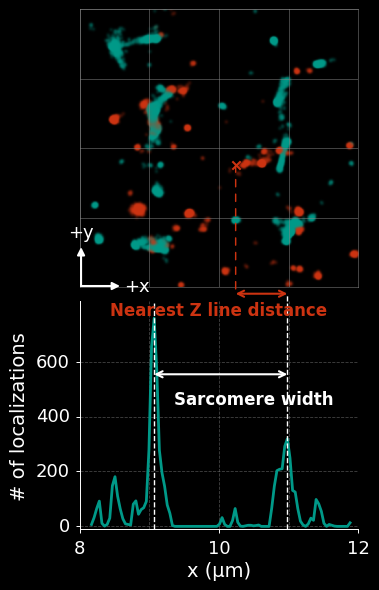

In [13]:
display(fig)

In [10]:
savepath = "../../figures/2b"
save_panel(fig, savepath, formats=("svg",))

[PosixPath('../../figures/2b.svg')]

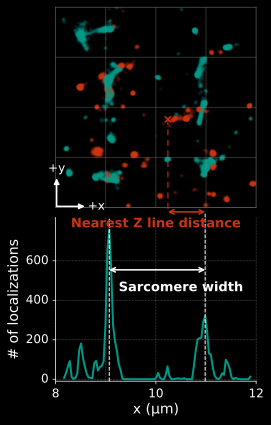

In [11]:
display(SVG(filename=str(savepath+".svg")))
plt.close(fig)